In [1]:
import pickle
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

In [2]:
DATA_DIR = r"C:\Users\sheer\Downloads\Earthquake_datasets"

df1 = pd.read_csv(f"{DATA_DIR}\\earthquake_1995-2023.csv")
df2 = pd.read_csv(f"{DATA_DIR}\\earthquake_data.csv")

# Combine datasets and drop duplicate entries
df = pd.concat([df1, df2], ignore_index=True).drop_duplicates()
pd.set_option("display.max_columns", None)
df.head()

,title,magnitude,date_time,cdi,mmi,alert,tsunami,sig,net,nst,dmin,gap,magType,depth,latitude,longitude,location,continent,country
0,"M 6.5 - 42 km W of Sola, Vanuatu",6.5,16-08-2023 12:47,7,4,green,0,657,us,114,7.177000,25.0,mww,192.955,-13.8814,167.1580,"Sola, Vanuatu",NaN,Vanuatu
1,"M 6.5 - 43 km S of Intipucá, El Salvador",6.5,19-07-2023 00:22,8,6,yellow,0,775,us,92,0.679000,40.0,mww,69.727,12.8140,-88.1265,"Intipucá, El Salvador",NaN,NaN
2,"M 6.6 - 25 km ESE of Loncopué, Argentina",6.6,17-07-2023 03:05,7,5,green,0,899,us,70,1.634000,28.0,mww,171.371,-38.1911,-70.3731,"Loncopué, Argentina",South America,Argentina
3,"M 7.2 - 98 km S of Sand Point, Alaska",7.2,16-07-2023 06:48,6,6,green,1,860,us,173,0.907000,36.0,mww,32.571,54.3844,-160.6990,"Sand Point, Alaska",NaN,NaN
4,M 7.3 - Alaska Peninsula,7.3,16-07-2023 06:48,0,5,NaN,1,820,at,79,0.879451,172.8,Mi,21.000,54.4900,-160.7960,Alaska Peninsula,NaN,NaN


In [3]:
df.info()

# Handle missing alert entries as a distinct 'none' category
df["alert"] = df["alert"].fillna("none")

# Retain the relevant seismic, geographic, and metadata features
selected_features = [
    "magnitude",
    "cdi",
    "mmi",
    "sig",
    "nst",
    "dmin",
    "gap",
    "depth",
    "latitude",
    "longitude",
    "alert",
    "magType",
    "net",
    "tsunami",
]

df = df[selected_features].copy()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   title      1000 non-null   object 
 1   magnitude  1000 non-null   float64
 2   date_time  1000 non-null   object 
 3   cdi        1000 non-null   int64  
 4   mmi        1000 non-null   int64  
 5   alert      449 non-null    object 
 6   tsunami    1000 non-null   int64  
 7   sig        1000 non-null   int64  
 8   net        1000 non-null   object 
 9   nst        1000 non-null   int64  
 10  dmin       1000 non-null   float64
 11  gap        1000 non-null   float64
 12  magType    1000 non-null   object 
 13  depth      1000 non-null   float64
 14  latitude   1000 non-null   float64
 15  longitude  1000 non-null   float64
 16  location   994 non-null    object 
 17  continent  284 non-null    object 
 18  country    651 non-null    object 
dtypes: float64(6), int64(5), object(8)
memory usage: 156.2

In [4]:
# Target distribution
print(df["tsunami"].value_counts())
print(
    f"Tsunami occurrence rate: {(df['tsunami'].mean() * 100):.2f}%"
)

tsunami
0    675
1    325
Name: count, dtype: int64
Tsunami occurrence rate: 32.50%


Magnitude Mean: 6.940150000000001
Magnitude Median: 6.8


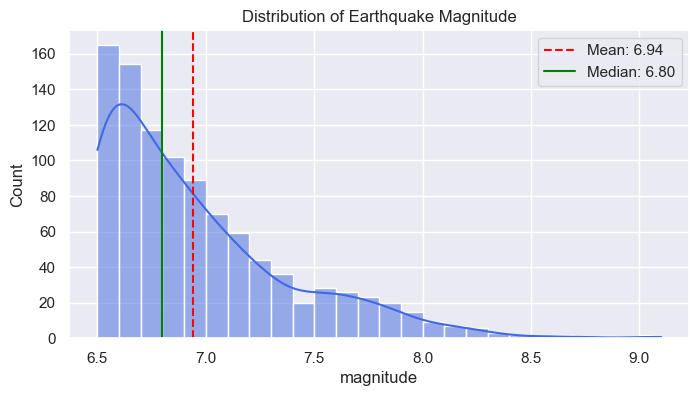

Significance Mean: 847.915
Significance Median: 744.0


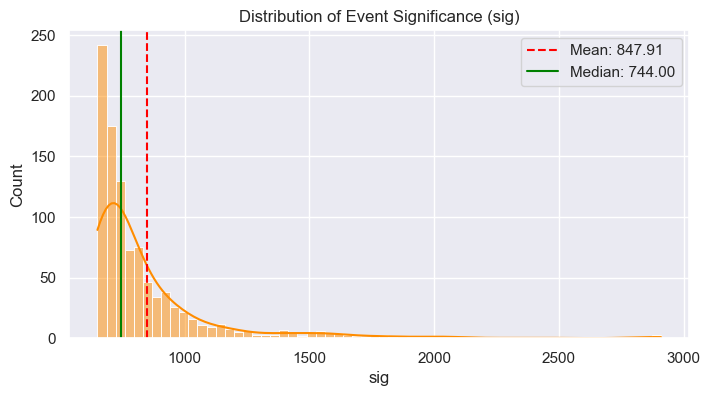

In [5]:
sns.set_theme(style="darkgrid")

# 1. Distribution of Earthquake Magnitude
plt.figure(figsize=(8, 4))
sns.histplot(df["magnitude"], kde=True, color="royalblue")
plt.title("Distribution of Earthquake Magnitude")

mag_mean = df["magnitude"].mean()
mag_median = df["magnitude"].median()
print("Magnitude Mean:", mag_mean)
print("Magnitude Median:", mag_median)

plt.axvline(
    mag_mean, color="red", linestyle="--", label=f"Mean: {mag_mean:.2f}"
)
plt.axvline(
    mag_median,
    color="green",
    linestyle="-",
    label=f"Median: {mag_median:.2f}",
)
plt.legend()
plt.show()

# 2. Distribution of Seismic Event Significance (sig)
plt.figure(figsize=(8, 4))
sns.histplot(df["sig"], kde=True, color="darkorange")
plt.title("Distribution of Event Significance (sig)")

sig_mean = df["sig"].mean()
sig_median = df["sig"].median()
print("Significance Mean:", sig_mean)
print("Significance Median:", sig_median)

plt.axvline(
    sig_mean, color="red", linestyle="--", label=f"Mean: {sig_mean:.2f}"
)
plt.axvline(
    sig_median,
    color="green",
    linestyle="-",
    label=f"Median: {sig_median:.2f}",
)
plt.legend()
plt.show()

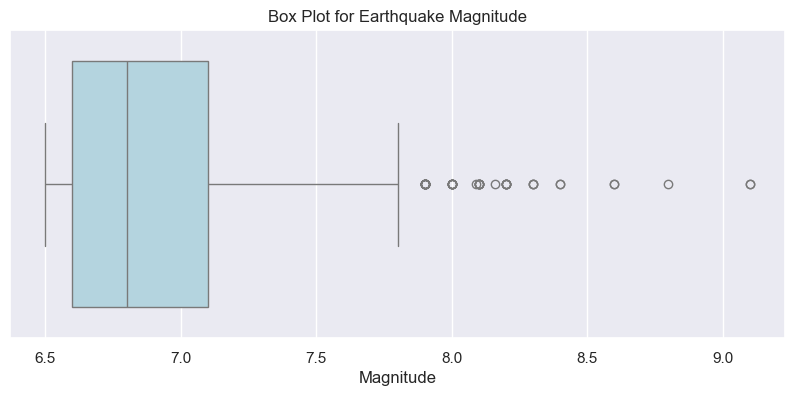

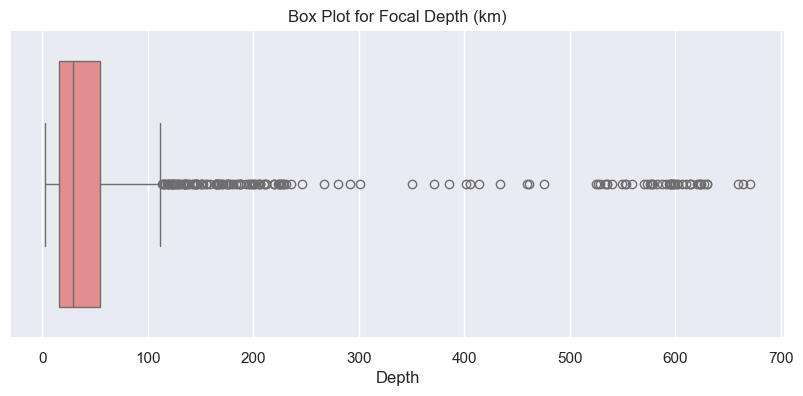

In [6]:
# Box plots for continuous seismic readings
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["magnitude"], color="lightblue")
plt.title("Box Plot for Earthquake Magnitude")
plt.xlabel("Magnitude")
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(x=df["depth"], color="lightcoral")
plt.title("Box Plot for Focal Depth (km)")
plt.xlabel("Depth")
plt.show()

In [7]:
def replace_outliers_with_median(data, column):
  Q1 = data[column].quantile(0.25)
  Q3 = data[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  median_val = data[column].median()
  data[column] = data[column].apply(
      lambda x: median_val if (x < lower_bound or x > upper_bound) else x
  )
  return data


for col in ["magnitude", "depth", "sig"]:
  df = replace_outliers_with_median(df, col)

In [8]:
object_columns = ["alert", "magType", "net"]
encoders = {}

for col in object_columns:
  le = LabelEncoder()
  df[col] = le.fit_transform(df[col].astype(str))
  encoders[col] = le

# Save encoders
with open(f"{DATA_DIR}\\encoders.pkl", "wb") as f:
  pickle.dump(encoders, f)

print("Encoders saved successfully!")

Encoders saved successfully!


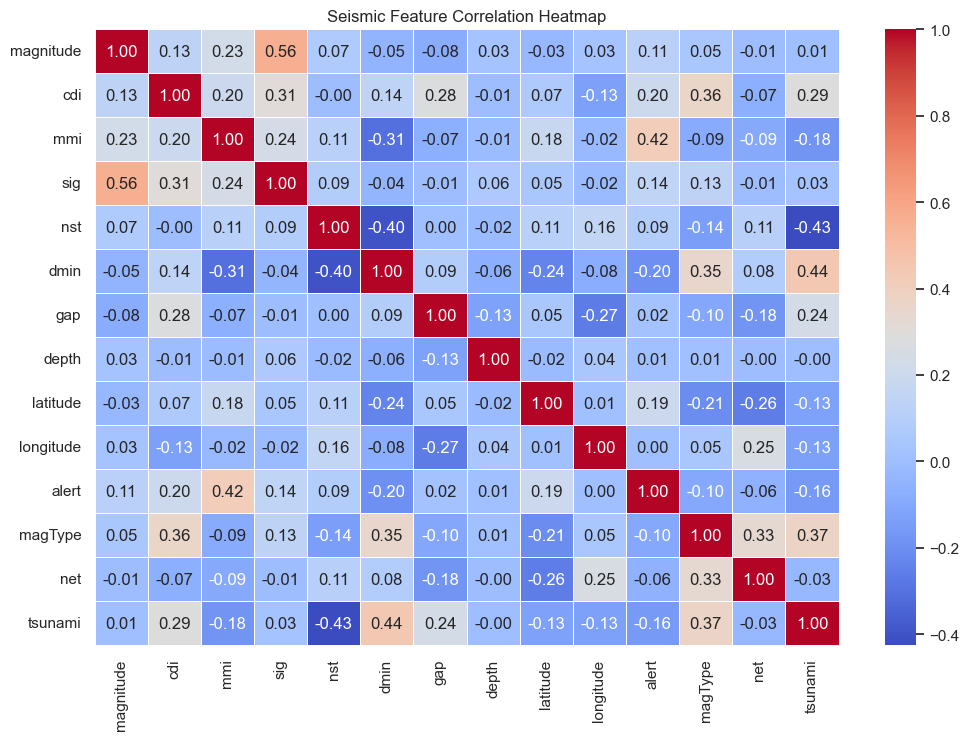

In [9]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Seismic Feature Correlation Heatmap")
plt.show()

In [10]:
X = df.drop("tsunami", axis=1)
y = df["tsunami"]

xtrain, xtest, ytrain, ytest = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Apply SMOTE on the training set
smote = SMOTE(random_state=42)
xtrain_smote, ytrain_smote = smote.fit_resample(xtrain, ytrain)

print(
    f"Class distribution before SMOTE:\n{ytrain.value_counts()}\n"
    f"Class distribution after SMOTE:\n{ytrain_smote.value_counts()}"
)

Class distribution before SMOTE:
tsunami
0    540
1    260
Name: count, dtype: int64
Class distribution after SMOTE:
tsunami
0    540
1    540
Name: count, dtype: int64


In [11]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss"),
}

cv_scores = {}

for model_name, model in models.items():
  print(f"Training {model_name} with default parameters...")
  scores = cross_val_score(
      model, xtrain_smote, ytrain_smote, cv=5, scoring="accuracy"
  )
  cv_scores[model_name] = scores
  print(f"{model_name} Cross-Validation Accuracy: {np.mean(scores):.4f}")
  print("-" * 50)

Training Decision Tree with default parameters...
Decision Tree Cross-Validation Accuracy: 0.9361
--------------------------------------------------
Training Random Forest with default parameters...
Random Forest Cross-Validation Accuracy: 0.9370
--------------------------------------------------
Training XGBoost with default parameters...
XGBoost Cross-Validation Accuracy: 0.9500
--------------------------------------------------


In [12]:
# Hyperparameter grids
param_grid_dt = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 5, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

param_grid_rf = {
    "n_estimators": [50, 100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "bootstrap": [True, False],
}

param_grid_xgb = {
    "n_estimators": [50, 100, 200, 300],
    "max_depth": [3, 5, 7, 10],
    "learning_rate": [0.01, 0.1, 0.2, 0.3],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}

random_search_dt = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=param_grid_dt,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=42,
)

random_search_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_grid_rf,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=42,
)

random_search_xgb = RandomizedSearchCV(
    estimator=XGBClassifier(random_state=42, eval_metric="logloss"),
    param_distributions=param_grid_xgb,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=42,
)

print("Tuning Decision Tree...")
random_search_dt.fit(xtrain_smote, ytrain_smote)

print("Tuning Random Forest...")
random_search_rf.fit(xtrain_smote, ytrain_smote)

print("Tuning XGBoost...")
random_search_xgb.fit(xtrain_smote, ytrain_smote)

Tuning Decision Tree...
Tuning Random Forest...
Tuning XGBoost...


,estimator,"XGBClassifier...ree=None, ...)"
,param_distributions,"{'colsample_bytree': [0.6, 0.8, ...], 'learning_rate': [0.01, 0.1, ...], 'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...], ...}"
,n_iter,20
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


Best Model: XGBoost
Best Hyperparameters: {'subsample': 1.0, 'n_estimators': 50, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Best Cross-Validation Accuracy: 0.9491

Accuracy Score on Test Set: 0.9350

Confusion Matrix:
[[126   9]
 [  4  61]]


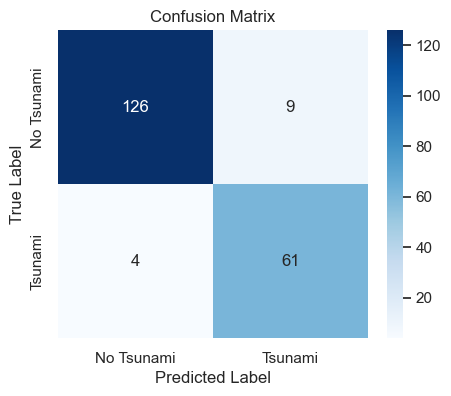


Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.93      0.95       135
           1       0.87      0.94      0.90        65

    accuracy                           0.94       200
   macro avg       0.92      0.94      0.93       200
weighted avg       0.94      0.94      0.94       200

Model saved successfully as tsunami_model.pkl!


In [13]:
tuned_models = {
    "Decision Tree": random_search_dt,
    "Random Forest": random_search_rf,
    "XGBoost": random_search_xgb,
}

best_name = max(tuned_models, key=lambda x: tuned_models[x].best_score_)
best_model = tuned_models[best_name].best_estimator_
best_score = tuned_models[best_name].best_score_

print("Best Model:", best_name)
print("Best Hyperparameters:", tuned_models[best_name].best_params_)
print(f"Best Cross-Validation Accuracy: {best_score:.4f}")

# Evaluation on Test Data
ytest_pred = best_model.predict(xtest)
print(f"\nAccuracy Score on Test Set: {accuracy_score(ytest, ytest_pred):.4f}")

print("\nConfusion Matrix:")
cm = confusion_matrix(ytest, ytest_pred)
print(cm)

# Visual Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Tsunami", "Tsunami"],
    yticklabels=["No Tsunami", "Tsunami"],
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

print("\nClassification Report:")
print(classification_report(ytest, ytest_pred))

# Save the best model
joblib.dump(best_model, f"{DATA_DIR}\\tsunami_model.pkl")
print("Model saved successfully as tsunami_model.pkl!")

In [14]:
import os
import pickle
import gradio as gr
import joblib
import pandas as pd

MODEL_DIR = r"C:\Users\sheer\Downloads\Earthquake_datasets"

# Load saved model and encoders
model = joblib.load(os.path.join(MODEL_DIR, "tsunami_model.pkl"))
with open(os.path.join(MODEL_DIR, "encoders.pkl"), "rb") as f:
  encoders = pickle.load(f)


def predict_tsunami(
    magnitude,
    cdi,
    mmi,
    sig,
    nst,
    dmin,
    gap,
    depth,
    latitude,
    longitude,
    magType,
    net,
):
  # Encode categorical variables using loaded encoders
  magType_enc = encoders["magType"].transform([str(magType)])[0]
  net_enc = encoders["net"].transform([str(net)])[0]

  # Assemble input DataFrame
  input_data = pd.DataFrame({
      "magnitude": [float(magnitude)],
      "cdi": [float(cdi)],
      "mmi": [float(mmi)],
      "sig": [float(sig)],
      "nst": [float(nst)],
      "dmin": [float(dmin)],
      "gap": [float(gap)],
      "depth": [float(depth)],
      "latitude": [float(latitude)],
      "longitude": [float(longitude)],
      "magType": [magType_enc],
      "net": [net_enc],
  })

  prediction = model.predict(input_data)[0]
  probability = (
      model.predict_proba(input_data)[0][1]
      if hasattr(model, "predict_proba")
      else None
  )

  if prediction == 1:
    return (
        f"🚨 TSUNAMI LIKELY\nProbability: {probability*100:.1f}%\nAlert Level:"
        " Warning issued based on seismic metrics."
    )
  else:
    prob_str = (
        f"\nProbability: {probability*100:.1f}%"
        if probability is not None
        else ""
    )
    return (
        "✅ NO TSUNAMI DETECTED"
        + prob_str
        + "\nSeismic parameters remain below critical tsunami thresholds."
    )


# Build Gradio UI
with gr.Blocks(title="Earthquake & Tsunami Warning System") as demo:
  gr.Markdown("# <center>🌊Tsunami Risk Prediction System</center>")
  gr.Markdown("### Enter the seismic, station, and event parameters below:")

  with gr.Row():
    magnitude = gr.Number(label="Magnitude (Richter)", value=6.8)
    cdi = gr.Number(label="Max Reported Intensity (CDI)", value=6.0)
    mmi = gr.Number(label="Instrumental Intensity (MMI)", value=6.0)
    sig = gr.Number(label="Event Significance (sig)", value=700)

  with gr.Row():
    depth = gr.Number(label="Focal Depth (km)", value=25.0)
    latitude = gr.Number(label="Latitude", value=-5.20)
    longitude = gr.Number(label="Longitude", value=102.50)

  with gr.Row():
    nst = gr.Number(label="Number of Stations (nst)", value=80)
    dmin = gr.Number(label="Minimum Distance (dmin)", value=1.5)
    gap = gr.Number(label="Azimuthal Gap (gap)", value=30.0)

  with gr.Row():
    
    magType = gr.Dropdown(
        choices=encoders["magType"].classes_.tolist(),
        label="Magnitude Formula (magType)",
        value="mww",
    )
    net = gr.Dropdown(
        choices=encoders["net"].classes_.tolist(),
        label="Data Contributor Network (net)",
        value="us",
    )

  btn = gr.Button("Predict Tsunami Risk", variant="primary")
  output = gr.Textbox(label="Prediction Result", lines=3)

  btn.click(
      fn=predict_tsunami,
      inputs=[
          magnitude,
          cdi,
          mmi,
          sig,
          nst,
          dmin,
          gap,
          depth,
          latitude,
          longitude,
          magType,
          net,
      ],
      outputs=output,
  )

if __name__ == "__main__":
  demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [15]:



#Full details of Sample YES 
#{'magnitude': 7.2, 'cdi': 6, 'mmi': 6, 'sig': 860, 'nst': 173, 'dmin': 0.907, 'gap': 36.0, 'depth': 32.571, 'latitude': 54.3844, 'longitude': -160.699,  'magType': 'mww', 'net': 'us', 'tsunami': 1}

#Full details of Sample NO 
#{'magnitude': 6.5, 'cdi': 7, 'mmi': 4, 'sig': 657, 'nst': 114, 'dmin': 7.177, 'gap': 25.0, 'depth': 192.955, 'latitude': -13.8814, 'longitude': 167.158,  'magType': 'mww', 'net': 'us', 'tsunami': 0}



In [16]:
#http://127.0.0.1:7860](http://127.0.0.1:7860)